# Online Retail II — End-to-End Data Analysis

**Goal:** Understand retail sales, product performance, geography, customer purchasing behaviour, seasonality, and data quality.

**Dataset:** `online_retail_II.csv`.

## Methodology and definitions

- The original file has transaction-line records, not one row per order. An invoice can contain multiple product lines.
- Exact duplicate rows are removed in a separate working DataFrame; the original DataFrame is preserved.
- `Revenue = Quantity × Price` is calculated at line level.
- For the primary **sales analysis**, we include rows where the invoice ID does not start with `C`, quantity is positive, and price is positive. This is an explicit analytical rule, not a claim that every excluded row is invalid.
- Customer analysis only includes rows with a known `Customer ID`.
- The source includes non-merchandise/accounting entries, returns and unusual records; results depend on these stated rules.
- Each code cell is followed by a result-analysis note. Notes state dataset-level findings, not universal business conclusions.

## 1. Load the data and inspect its structure

**Concept:** A DataFrame is a tabular structure. We inspect row count, column names, data types and a small sample before making transformations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


df = pd.read_csv(r"C:\DATA ANALYTICS\DA WITH PYTHON\online_retail_II.csv")
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

Shape: (1067371, 8)

Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom



Data types:


,dtype
Invoice,str
StockCode,str
Description,str
Quantity,int64
InvoiceDate,str
Price,float64
Customer ID,float64
Country,str


## 2. Convert dates and audit missing values

**Concept:** Date strings need datetime conversion for monthly analysis. Missingness is measured before deciding how to handle it; customer IDs are not imputed because they identify customers.

In [2]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing %": df.isna().mean().mul(100)
}).sort_values("Missing values", ascending=False)

print("Date dtype:", df["InvoiceDate"].dtype)
print("Invalid/missing dates:", df["InvoiceDate"].isna().sum())
display(missing_summary[missing_summary["Missing values"] > 0])

Date dtype: datetime64[us]
Invalid/missing dates: 0


,Missing values,Missing %
Customer ID,243007,22.77
Description,4382,0.41


**Result analysis:** The raw dataset has **4,382 missing descriptions before duplicate removal in the earlier audit** and many missing customer IDs. After exact duplicate removal, there are **4,275 missing descriptions** and **235,151 missing customer IDs**. Customer-level analysis will use identified customers only; overall transaction analysis can retain rows with missing IDs.

## 3. Remove exact duplicates in a working copy

**Concept:** Exact duplicate rows match across all columns. We remove only extra exact copies, preserve the original `df`, and verify the result.

In [3]:
duplicate_count = int(df.duplicated().sum())
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Exact duplicate rows removed:", duplicate_count)
print("Rows after deduplication:", len(df_clean))
print("Remaining exact duplicates:", int(df_clean.duplicated().sum()))

Original rows: 1067371
Exact duplicate rows removed: 34335
Rows after deduplication: 1033036
Remaining exact duplicates: 0


**Result analysis:** **34,335** extra exact duplicate rows were removed, leaving **1,033,036 rows**. Verification should report zero remaining exact duplicates. This does not remove all repeated products or invoice lines—only rows identical across every column.

## 4. FEATURE ENGINEERING & EXTRACTION


In [4]:
df_clean["Invoice"] = df_clean["Invoice"].astype("string")
df_clean["IsCancellation"] = df_clean["Invoice"].str.startswith("C", na=False)
df_clean["IsNegativeQuantity"] = df_clean["Quantity"] < 0
df_clean["IsZeroPrice"] = df_clean["Price"] == 0
df_clean["IsNegativePrice"] = df_clean["Price"] < 0

quality_counts = pd.Series({
    "Cancellation-style rows": int(df_clean["IsCancellation"].sum()),
    "Negative quantity rows": int(df_clean["IsNegativeQuantity"].sum()),
    "Zero-price rows": int(df_clean["IsZeroPrice"].sum()),
    "Negative-price rows": int(df_clean["IsNegativePrice"].sum()),
    "Missing Customer ID": int(df_clean["Customer ID"].isna().sum()),
    "Missing Description": int(df_clean["Description"].isna().sum())
}, name="Rows")
display(quality_counts.to_frame())

,Rows
Cancellation-style rows,19104
Negative quantity rows,22496
Zero-price rows,6014
Negative-price rows,5
Missing Customer ID,235151
Missing Description,4275


**Result analysis:** After deduplication, the data contains **19,104 cancellation-style rows**, **22,496 negative-quantity rows**, **6,014 zero-price rows**, and **5 negative-price rows**. These groups can overlap, so their counts must not be added together as if they were distinct records.

In [5]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

sales = df_clean[
    (~df_clean["IsCancellation"]) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

sales["Month"] = sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

print("Sales-analysis rows:", len(sales))
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())
print("Sales revenue:", f"{sales['Revenue'].sum():,.2f}")
print("Unique invoices:", f"{sales['Invoice'].nunique():,}")
print("Known customers:", f"{sales['Customer ID'].nunique():,}")
print("Countries:", sales["Country"].nunique())

Sales-analysis rows: 1007913
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Sales revenue: 20,476,260.45
Unique invoices: 40,077
Known customers: 5,878
Countries: 43


**Result analysis:** Under this project's stated sales filter, **1,007,913 rows** remain, with total line revenue of **20,476,260.45** (in the dataset's price currency), **40,077 unique invoices**, **5,878 identifiable customers**, and **43 countries**. This is a rule-defined sales measure, not necessarily the company's audited accounting revenue.

## OUTLIER ANALYSIS

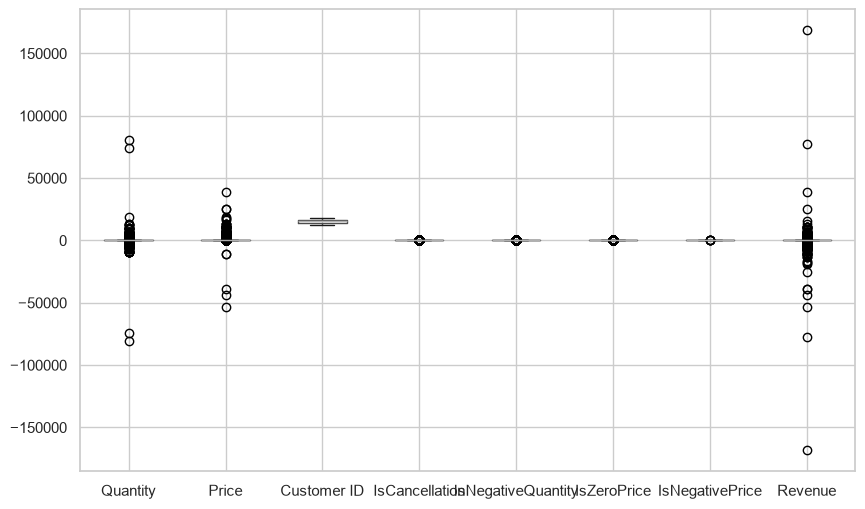

In [6]:
plt.figure(figsize=(10,6))
df_clean.boxplot()
plt.show()

Severe Data Skewness: Quantity, Price, and Revenue contain massive extreme outliers ($\pm 80,000$ units; revenue dropping to $-\$168,000+$), driven by unhandled bulk cancellations, bad debt, and ledger adjustments.Plot Scale Distortion: Mixing high-variance monetary values with Customer ID numbers and binary 0/1 flags flattens the boxplots near zero, hiding real data distributions.

# UNIVARIATE ANALYSIS

## 1.Quantity and Unit Price

**Concept:** Histograms show the distribution of a numerical variable. Skew and extreme values can make means unrepresentative, so medians and percentiles are also useful.

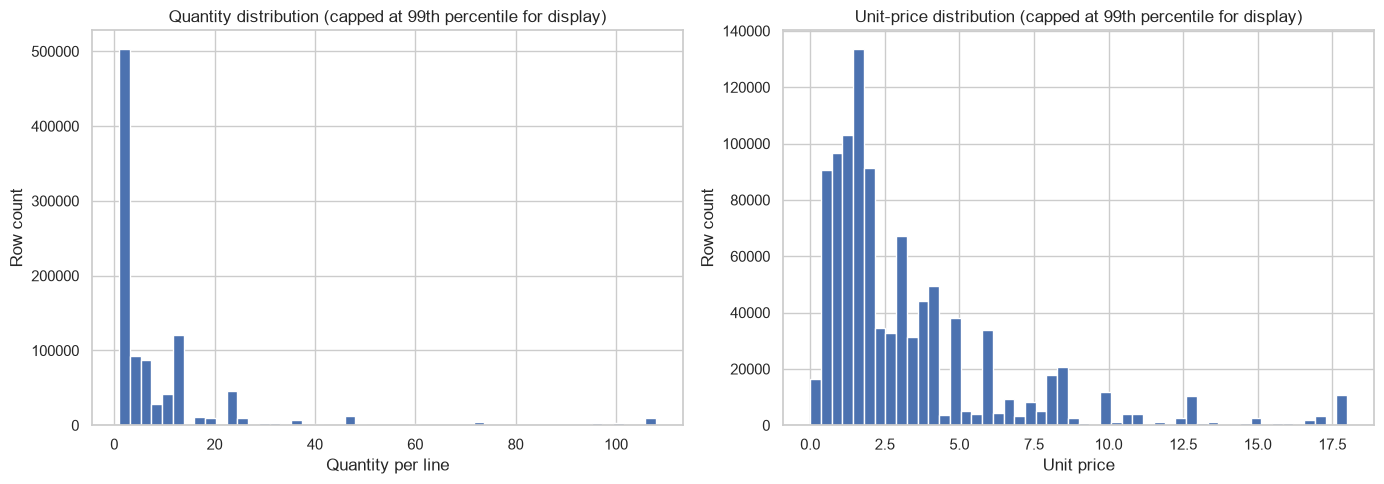

,count,mean,std,min,50%,90%,95%,99%,max
Quantity,"1,007,913.00",11.12,128.47,1.00,4.00,24.00,31.00,108.00,"80,995.00"
Price,"1,007,913.00",4.07,50.43,0.00,2.10,7.95,9.95,18.00,"25,111.09"
Revenue,"1,007,913.00",20.32,205.72,0.00,10.08,33.06,60.00,184.59,"168,469.60"


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
quantity_cap = sales["Quantity"].quantile(0.99)
price_cap = sales["Price"].quantile(0.99)
axes[0].hist(sales["Quantity"].clip(upper=quantity_cap), bins=50)
axes[0].set_title("Quantity distribution (capped at 99th percentile for display)")
axes[0].set_xlabel("Quantity per line")
axes[0].set_ylabel("Row count")

axes[1].hist(sales["Price"].clip(upper=price_cap), bins=50)
axes[1].set_title("Unit-price distribution (capped at 99th percentile for display)")
axes[1].set_xlabel("Unit price")
axes[1].set_ylabel("Row count")
plt.tight_layout()
plt.show()

display(sales[["Quantity", "Price", "Revenue"]].describe(
    percentiles=[.5, .9, .95, .99]
).T)

**Result analysis:** The charts cap values at the 99th percentile **for visualization only**; the underlying `sales` data is not capped or modified. Compare the median with the mean and upper percentiles to understand how a small number of large line items may influence totals.

## 2. Country contribution — pie chart

**Concept:** The bar chart compares countries precisely; the pie chart summarizes concentration. A pie chart is most useful with a small number of categories, so we show the top five countries plus all remaining countries combined.

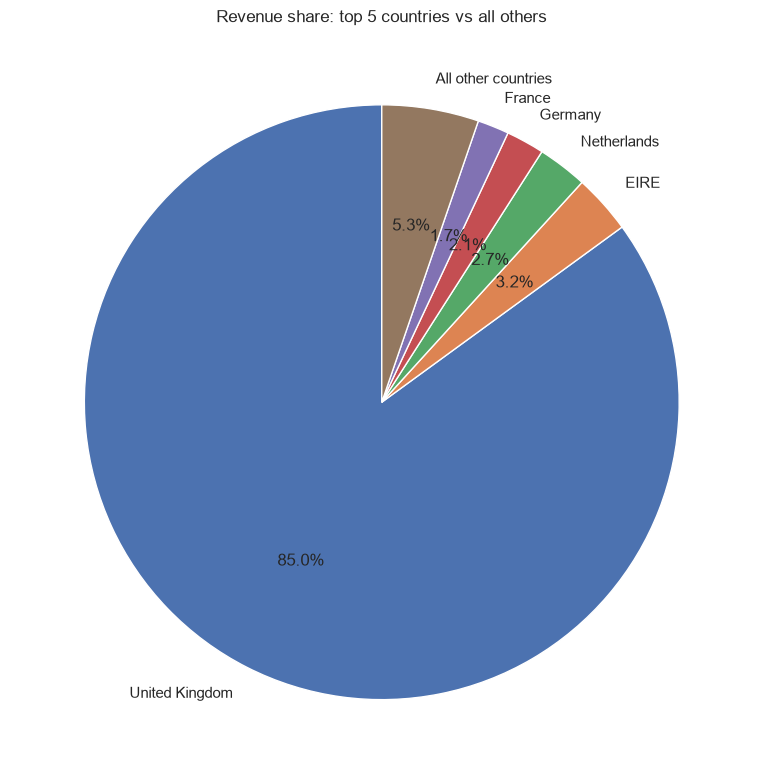

Top country revenue share: 85.0%


In [8]:
country_revenue=(sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False))
top5 = country_revenue.head(5)
other_revenue = country_revenue.iloc[5:].sum()
pie_values = list(top5.values) + [other_revenue]
pie_labels = list(top5.index) + ["All other countries"]
plt.figure(figsize=(8, 8))
plt.pie(pie_values, labels=pie_labels, autopct="%1.1f%%", startangle=90)
plt.title("Revenue share: top 5 countries vs all others")
plt.tight_layout()
plt.show()

print("Top country revenue share:", f"{country_revenue.iloc[0] / country_revenue.sum():.1%}")

**Result analysis:** The **United Kingdom** contributes approximately **85.0%** of revenue. Revenue is highly concentrated geographically in this filtered dataset; international expansion or diversification would require additional business context before making recommendations.

## 3. Customer analysis — RFM summary

**Concept:** RFM means Recency, Frequency and Monetary:
- **Recency:** days since the customer's last observed purchase (smaller is more recent).
- **Frequency:** number of distinct invoices.
- **Monetary:** total line revenue in the sales-analysis dataset.

This is historical descriptive segmentation, not predictive customer lifetime value.

In [9]:
rfm = sales.groupby("Customer ID").agg(
    RecencyDays=("InvoiceDate", lambda x: (sales["InvoiceDate"].max() + pd.Timedelta(days=1) - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")).reset_index()

# --- Plot 1: RFM Distribution Histograms ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Recency (Days since last order)
sns.histplot(rfm["RecencyDays"], bins=30, ax=axes[0], color="#2b5c8f", kde=True)
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Customer Count")

# Frequency (Capped at 99th percentile for clean display)
freq_cap = rfm["Frequency"].quantile(0.99)
axes[1].hist(rfm["Frequency"].clip(upper=freq_cap), bins=25, color="#e67e22", edgecolor="white")
axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Number of Invoices (Capped)")
axes[1].set_ylabel("Customer Count")

# Monetary (Capped at 95th percentile for clean display)
monetary_cap = rfm["Monetary"].quantile(0.95)
axes[2].hist(rfm["Monetary"].clip(upper=monetary_cap), bins=25, color="#27ae60", edgecolor="white")
axes[2].set_title("Monetary Distribution")
axes[2].set_xlabel("Total Revenue ($) (Capped)")
axes[2].set_ylabel("Customer Count")

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

**Result Analysis** : Recency Plot: Shows how active your customer base is. A heavy concentration near 0 days means most customers bought recently, while a spike on the far right indicates a large chunk of churned/dormant customers.

Frequency Plot: Visualizes customer loyalty. You'll likely see a massive bar at Frequency = 1 (one-time buyers), showing how many buyers never return.

Monetary Plot: Shows customer spend levels. Most customers sit in the lower revenue bracket, while a long tail of big spenders stretches to the right.

# BIVARIATE ANALYSIS

## 1. Monthly Revenue Trend — Line chart

**Concept:** Aggregating revenue by month reduces transaction-level noise and helps reveal seasonality. Incomplete first/last months and changing coverage should be considered.

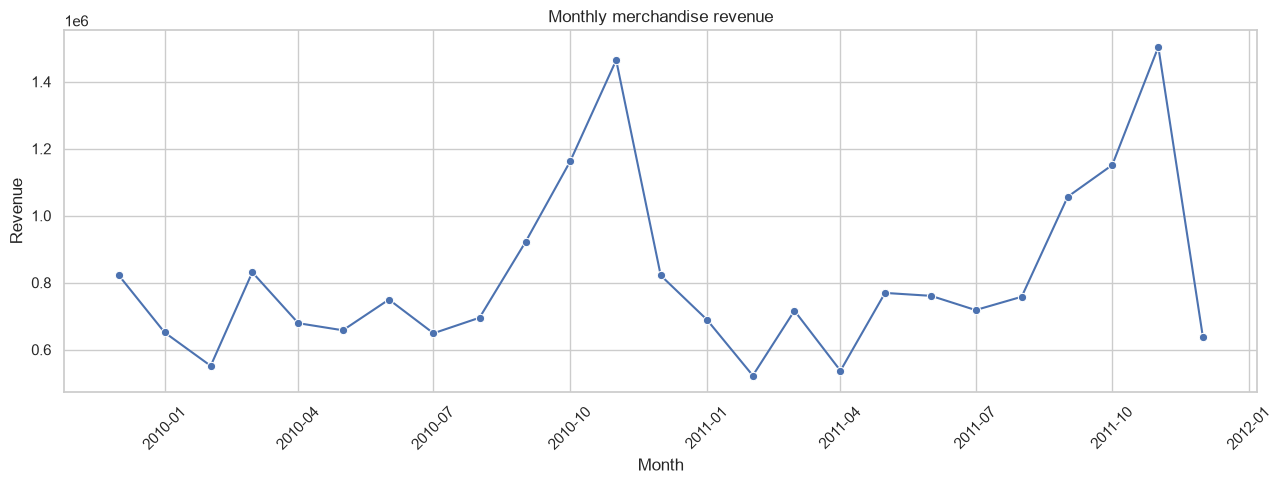

Highest-revenue month: 2011-11 (1,503,866.78)
Lowest-revenue month: 2011-02 (522,545.56)


In [ ]:
monthly = sales.groupby("Month").agg(
    Revenue=("Revenue", "sum"),
    Invoices=("Invoice", "nunique"),
    Units=("Quantity", "sum")
).reset_index()

plt.figure(figsize=(13, 5))
sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")
plt.title("Monthly merchandise revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

best_month = monthly.loc[monthly["Revenue"].idxmax()]
worst_month = monthly.loc[monthly["Revenue"].idxmin()]
print("Highest-revenue month:", best_month["Month"].strftime("%Y-%m"),
      f"({best_month['Revenue']:,.2f})")
print("Lowest-revenue month:", worst_month["Month"].strftime("%Y-%m"),
      f"({worst_month['Revenue']:,.2f})")

**Result analysis:** The highest-revenue month in the filtered dataset is **2011-11** at **1,503,866.78**; the lowest is **2011-02** at **522,545.56**. This describes observed monthly totals; it does not by itself establish why revenue changed.

## 2. Product performance — Top 10 Products by Revenue

**Concept:** Grouping by product description estimates which described items contribute the most revenue. Missing descriptions are retained as a group; product codes can be used for more reliable identification where names are missing or inconsistent.

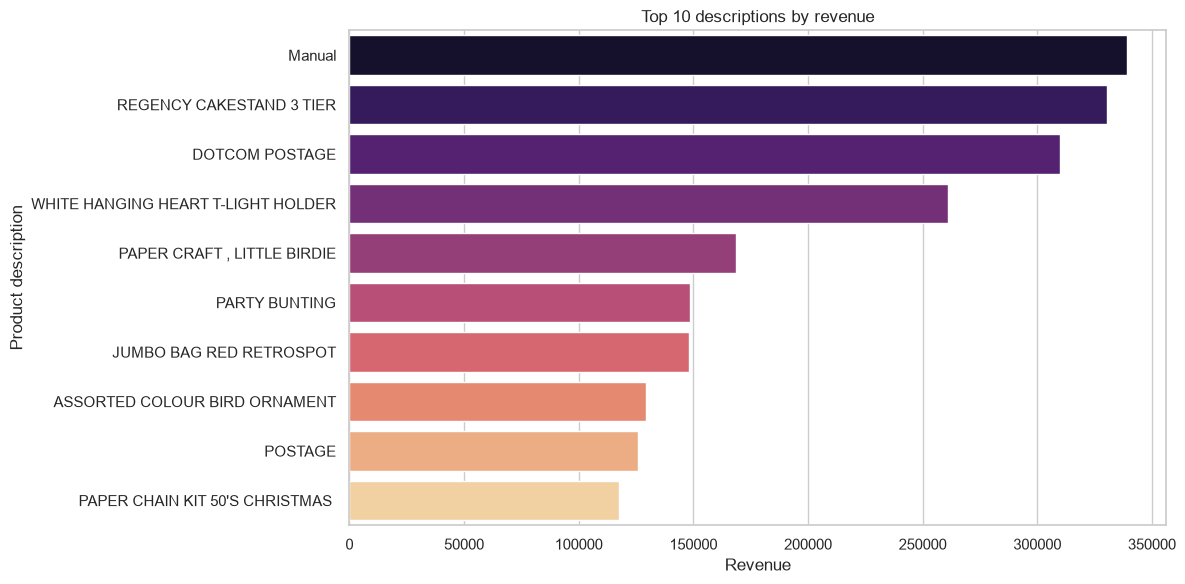

,Revenue
Description,
Manual,"339,241.29"
REGENCY CAKESTAND 3 TIER,"330,590.32"
DOTCOM POSTAGE,"309,854.11"
WHITE HANGING HEART T-LIGHT HOLDER,"260,990.22"
"PAPER CRAFT , LITTLE BIRDIE","168,469.60"
PARTY BUNTING,"148,318.28"
JUMBO BAG RED RETROSPOT,"148,073.47"
ASSORTED COLOUR BIRD ORNAMENT,"129,324.49"
POSTAGE,"125,682.42"


In [ ]:
product_revenue = sales.groupby("Description", dropna=False)["Revenue"].sum().sort_values(ascending=False)
top_products = product_revenue.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index,
            palette="magma", legend=False)
plt.title("Top 10 descriptions by revenue")
plt.xlabel("Revenue")
plt.ylabel("Product description")
plt.tight_layout()
plt.show()
display(top_products.to_frame("Revenue"))

**Result analysis:** The highest-revenue description in this filtered dataset is **Manual**, contributing **339,241.29**. Treat this as a description-level ranking rather than a perfectly normalized product catalog; entries such as manual adjustments or postage may appear alongside merchandise.

## 3. Scatter Plot — Quantity vs Unit price

**Concept:** A scatter plot compares two numerical variables. With over one million rows, we use a reproducible sample for readability. Correlation measures linear association, not causation.

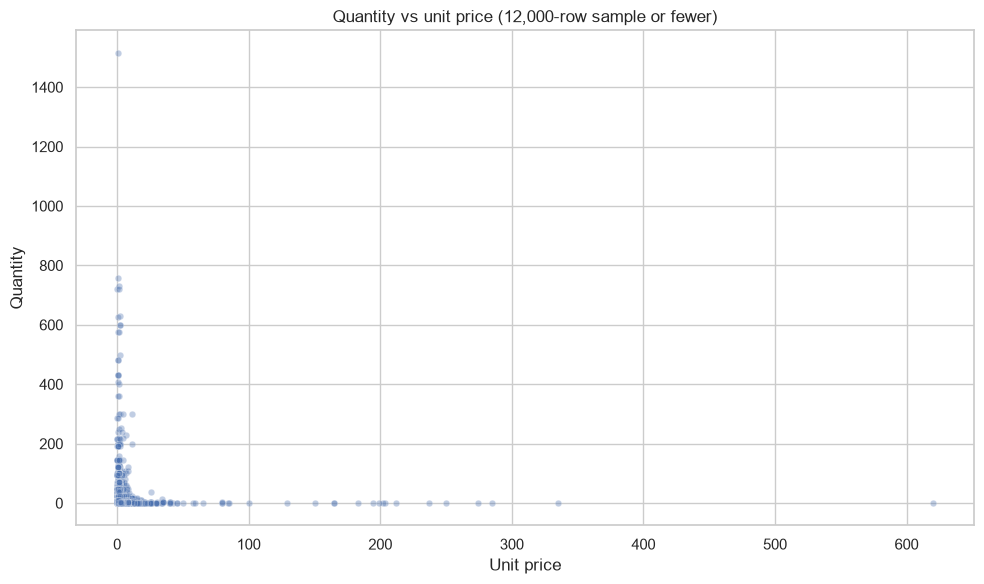

Pearson correlation (sample): -0.0537


In [ ]:
scatter_sample = sales.sample(n=min(12000, len(sales)), random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=scatter_sample, x="Price", y="Quantity", alpha=0.35, s=22)
plt.title("Quantity vs unit price (12,000-row sample or fewer)")
plt.xlabel("Unit price")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

print("Pearson correlation (sample):",
      f"{scatter_sample['Quantity'].corr(scatter_sample['Price']):.4f}")

**Result analysis:** Cheap items sell in bulk: All the tall vertical dots (quantities between 200 and 800+) happen when the unit price is very low—mostly under $10.   Expensive items sell in small amounts: As soon as the price goes above $20 or $50, the dots flatten out completely along the bottom. Nobody buys expensive items in bulk; customers usually just buy 1 or 2 at a time.   The "L-Shape" pattern: The dots form a clear "L" shape. This means price and quantity have an inverse relationship—as price increases, order quantity drops dramatically.   

Bulk Buyers are Price-Sensitive: Wholesale or high-volume buyers only exist for your cheapest products.

Non-Linear Trend: A standard linear correlation score (like Pearson) will look close to zero because the pattern is a steep curve, not a straight line.

## 4. Regression plot — Unit price vs Line revenue

**Concept:** A regression plot overlays a fitted straight line on sampled data. Because line revenue is quantity multiplied by price, this relationship is partly mathematical; it should not be interpreted as causal evidence.

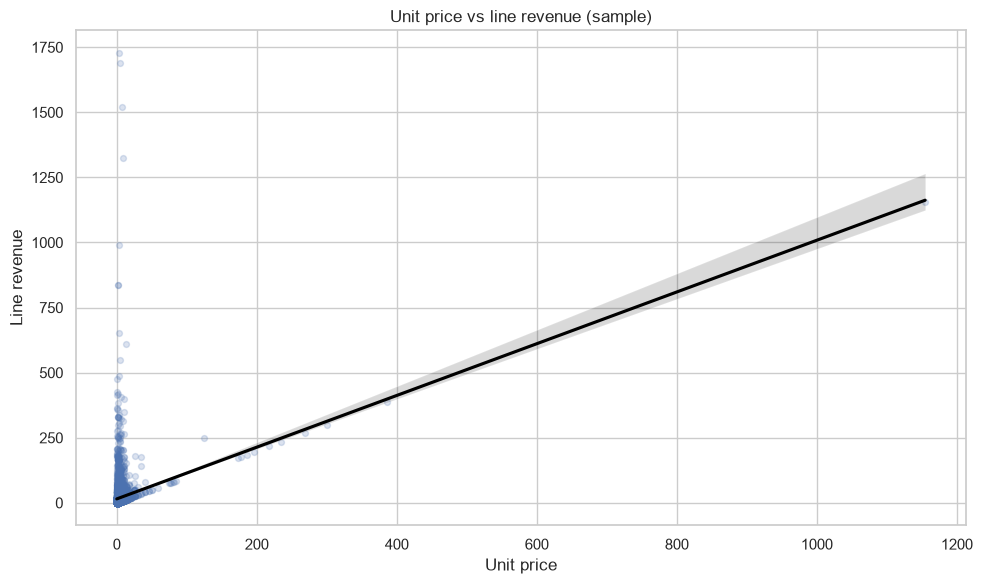

Sample size: 8000


In [ ]:
reg_sample = sales.sample(n=min(8000, len(sales)), random_state=7)
plt.figure(figsize=(10, 6))
sns.regplot(data=reg_sample, x="Price", y="Revenue",
            scatter_kws={"alpha": 0.2, "s": 18},
            line_kws={"color": "black"})
plt.title("Unit price vs line revenue (sample)")
plt.xlabel("Unit price")
plt.ylabel("Line revenue")
plt.tight_layout()
plt.show()
print("Sample size:", len(reg_sample))

**Result analysis:** The fitted line summarizes the average linear trend in the sample, but the wide spread is expected because line revenue depends on both price and quantity. Do not interpret this plot as proof that increasing unit price causes revenue to rise.

## 5. Violin plot — Line revenue across top countries

**Concept:** A violin plot shows distribution shape, not just average values. To avoid an unreadable chart, we use the five highest-revenue countries and cap the displayed revenue at the 95th percentile **for display only**.

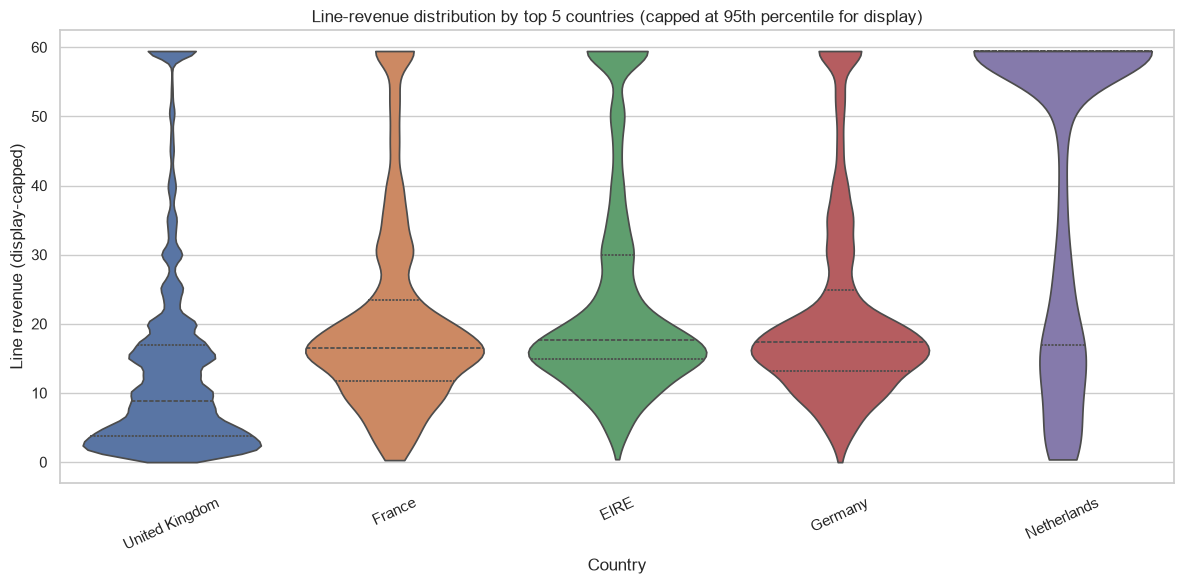

Display cap (95th percentile): 59.45


In [ ]:
top5_country_names = country_revenue.head(5).index.tolist()
violin_data = sales[sales["Country"].isin(top5_country_names)].copy()
cap = violin_data["Revenue"].quantile(0.95)
violin_data["Revenue_display"] = violin_data["Revenue"].clip(upper=cap)

plt.figure(figsize=(12, 6))
sns.violinplot(data=violin_data, x="Country", y="Revenue_display", inner="quartile",
               cut=0, hue="Country", legend=False)
plt.title("Line-revenue distribution by top 5 countries (capped at 95th percentile for display)")
plt.xlabel("Country")
plt.ylabel("Line revenue (display-capped)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
print("Display cap (95th percentile):", f"{cap:,.2f}")

**Result analysis:** United Kingdom (B2C / Retail focus): The shape is bottom-heavy, meaning most transactions are very small line items generating under $10. The UK represents high transaction volume from individual retail shoppers.

France, Germany, and EIRE (Mid-tier order values): These countries share a similar distribution shape with most purchases clustering between $12 and $25. They have fewer tiny $1–$5 orders compared to the UK.

Netherlands (B2B / Wholesale focus): The violin is top-heavy, expanding dramatically at the top $60 cap. Dutch orders consist of significantly higher line-revenue items, indicating wholesale or bulk buyers.

## 6. Boxplot — Quantity by top products

**Concept:** Boxplots compare medians, interquartile ranges and potential outliers. Here we choose the top five products by row frequency and display quantities capped at the 99th percentile to make the typical range visible.

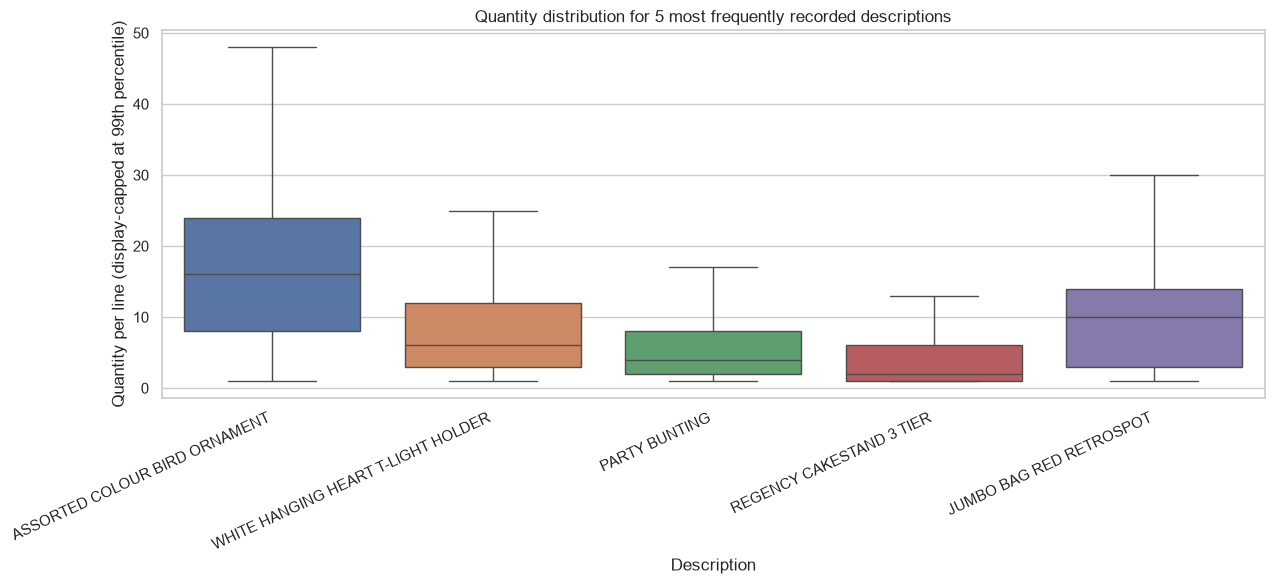

99th percentile display cap: 160.0


In [ ]:
top_frequent_products = sales["Description"].value_counts().head(5).index.tolist()
box_data = sales[sales["Description"].isin(top_frequent_products)].copy()
q_cap = box_data["Quantity"].quantile(0.99)
box_data["Quantity_display"] = box_data["Quantity"].clip(upper=q_cap)

plt.figure(figsize=(13, 6))
sns.boxplot(data=box_data, x="Description", y="Quantity_display",
            hue="Description",showfliers=False,legend=False)
plt.title("Quantity distribution for 5 most frequently recorded descriptions")
plt.xlabel("Description")
plt.ylabel("Quantity per line (display-capped at 99th percentile)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
print("99th percentile display cap:", q_cap)

**Result analysis:** Bird Ornaments sell in the largest batches: Assorted Colour Bird Ornament has the highest typical order quantity (median around 16 units) with single orders stretching up to nearly 50 units.

Cakestands are bought in very small numbers: Regency Cakestand 3 Tier has the lowest quantity per line (median of 1 to 2 units), as customers rarely buy multiple high-value display stands at once.

Jumbo Bags & T-Light Holders show steady multi-pack demand: Jumbo Bag Red Retrospot (median ~10) and White Hanging Heart T-Light Holder (median ~6) are consistently purchased in small bundles.

## 7. Scatter plot — Customer Frequency vs Monetary value

**Concept:** Each point represents one identifiable customer. The plot compares purchase frequency with total historical revenue; log scaling helps show both low- and high-value customers.

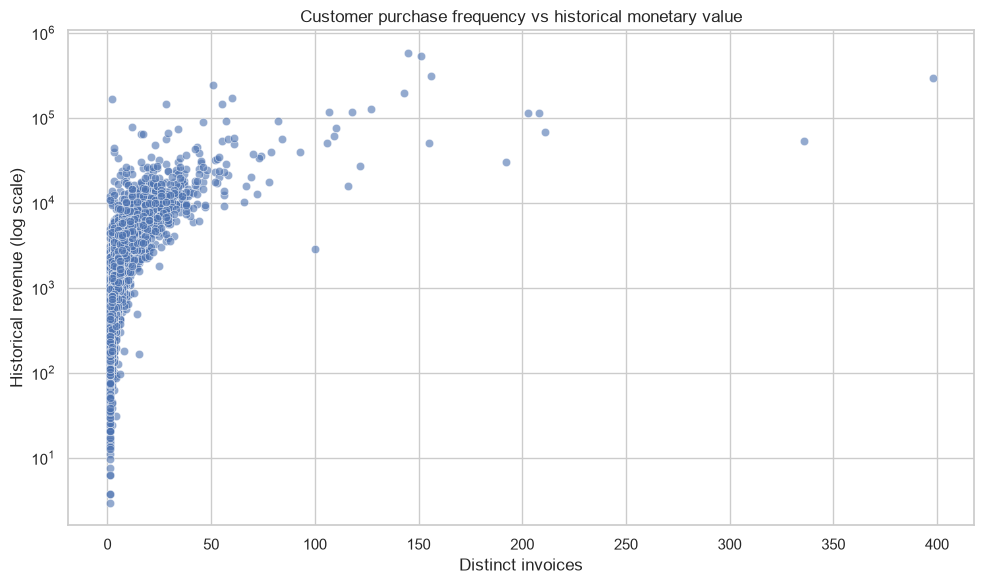

Median customer revenue: 867.74
Median customer invoice frequency: 3


In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", alpha=0.6)
plt.yscale("log")
plt.title("Customer purchase frequency vs historical monetary value")
plt.xlabel("Distinct invoices")
plt.ylabel("Historical revenue (log scale)")
plt.tight_layout()
plt.show()

print("Median customer revenue:", f"{rfm['Monetary'].median():,.2f}")
print("Median customer invoice frequency:", f"{rfm['Frequency'].median():.0f}")

**Result analysis:** The scatter plot helps identify customers with high invoice frequency, high historical spending, or both. The logarithmic y-axis compresses the long tail; visual distance on this axis is multiplicative rather than linear.

## 8. Cancellation-style records over time - Line Plot
**Concept:** Tracking cancellation-style rows by month can reveal when they occur. It is a count of rows, not a count of cancelled orders or monetary impact.

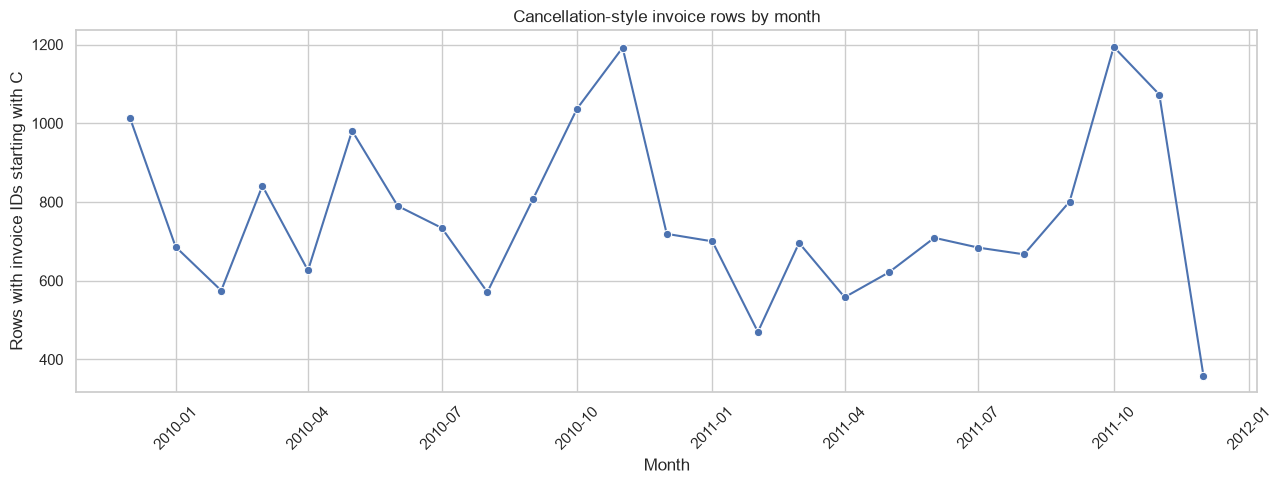

Cancellation-style rows: 19104
Months represented: 25


In [ ]:
cancel_rows = df_clean[df_clean["IsCancellation"] & df_clean["InvoiceDate"].notna()].copy()
cancel_rows["Month"] = cancel_rows["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
cancel_monthly = cancel_rows.groupby("Month").size().rename("Rows").reset_index()

plt.figure(figsize=(13, 5))
sns.lineplot(data=cancel_monthly, x="Month", y="Rows", marker="o")
plt.title("Cancellation-style invoice rows by month")
plt.xlabel("Month")
plt.ylabel("Rows with invoice IDs starting with C")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("Cancellation-style rows:", len(cancel_rows))
print("Months represented:", cancel_monthly["Month"].nunique())

**Result analysis:** The line chart describes monthly variation in cancellation-style row counts. Because an invoice can contain multiple rows, use distinct invoice counts or cancellation amounts for order-level/financial analysis.

# MULTIVARIATE ANALYSIS

# Correlation Heatmap

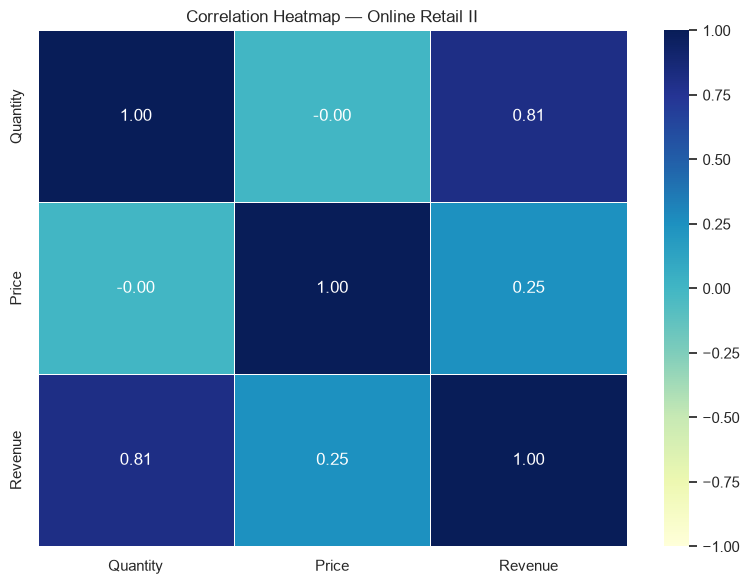

In [ ]:
# Select numerical variables for correlation analysis
corr_data = sales[["Quantity", "Price", "Revenue"]]

# Calculate the correlation matrix
corr_matrix = corr_data.corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap — Online Retail II")
plt.tight_layout()
plt.show()

### Correlation Heatmap Analysis

- The heatmap displays Pearson correlations between quantity, unit price, and line revenue.
- Positive coefficients indicate that two variables tend to increase together; negative coefficients indicate an inverse linear relationship.
- Revenue is calculated as quantity multiplied by price, so correlations involving revenue should be interpreted with caution.
- Correlation measures linear association and does not establish causation.

## 18. Final KPI dashboard and data-quality checks

**Concept:** A final KPI table summarizes the definitions used throughout the notebook. It is useful only when the inclusion rules are stated alongside the metrics.

In [ ]:
kpis = pd.Series({
    "Original rows": len(df),
    "Exact duplicate rows removed": duplicate_count,
    "Rows after deduplication": len(df_clean),
    "Sales-analysis rows": len(sales),
    "Sales-analysis revenue": sales["Revenue"].sum(),
    "Distinct sales invoices": sales["Invoice"].nunique(),
    "Identified customers": sales["Customer ID"].nunique(),
    "Countries represented": sales["Country"].nunique(),
    "Missing Customer IDs after deduplication": df_clean["Customer ID"].isna().sum(),
    "Cancellation-style rows after deduplication": df_clean["IsCancellation"].sum(),
    "Zero-price rows after deduplication": df_clean["IsZeroPrice"].sum()
}, name="Value")
display(kpis.to_frame())

assert df_clean.duplicated().sum() == 0
assert sales["Quantity"].gt(0).all()
assert sales["Price"].gt(0).all()
assert (~sales["IsCancellation"]).all()
print("Validation checks passed.")

,Value
Original rows,"1,067,371.00"
Exact duplicate rows removed,"34,335.00"
Rows after deduplication,"1,033,036.00"
Sales-analysis rows,"1,007,913.00"
Sales-analysis revenue,"20,476,260.45"
Distinct sales invoices,"40,077.00"
Identified customers,"5,878.00"
Countries represented,43.00
Missing Customer IDs after deduplication,"235,151.00"
Cancellation-style rows after deduplication,"19,104.00"


Validation checks passed.


**Result analysis:** The project has a reproducible rule-defined sales view with **1,007,913 rows**, **20,476,260.45** in line revenue, and **40,077 distinct invoices**. Validation checks confirm the sales subset contains positive quantities, positive prices and no cancellation-style invoice IDs. The raw and cleaned datasets are retained separately for auditability.

## 19. Conclusions and recommendations

1. **Geographic concentration:** The United Kingdom contributes the large majority of filtered revenue. Track non-UK markets separately before making expansion decisions.
2. **Seasonality:** Monthly revenue peaks in November in this dataset. Check whether this pattern repeats across years and whether partial months affect comparisons.
3. **Product ranking:** Revenue rankings include descriptions such as `Manual` and postage-related entries. Create a product/service classification before treating the ranking as merchandise-only.
4. **Customer retention:** RFM metrics can identify recent, frequent and high-spending customers. Customer IDs are missing for many rows, so customer insights apply only to identifiable customers.
5. **Data quality:** Keep cancellation, return, zero-price and accounting-adjustment records flagged rather than deleting them without context.
6. **Next improvements:** Build a cancellation/return value analysis, compare year-over-year months, normalize product codes/descriptions, and export a clean KPI table for a dashboard.

**Limitations:** This is a historical transaction dataset. The filtered revenue metric is defined for analysis and should not be presented as audited accounting revenue or profit. No costs are available, so profitability cannot be inferred.